# Tool-calling smoke test: analysis (SCRUM-23)

Reads one run of `scripts/smoke_tool_calling.py` (`runs/smoke-<timestamp>/results.jsonl`) and rebuilds:

1. the **results table per model** (the ticket's deliverable), with 95% confidence intervals,
2. a breakdown **per case group** (one tool, multi-step, no tool),
3. the **failures**, call by call against what was expected,
4. how the model fills **arguments** (filters, extra `limit`),
5. **latency** and **consistency** across the 3 trials.

Metric definitions are in the script's docstring. Rates leave out trials where a metric does not apply
(e.g. *no-tool OK* only counts cases that need no tool).

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml

from netllm.config import ROOT

pd.set_option("display.max_colwidth", 120)

# Latest run by default; set RUN to a specific folder to analyse another one.
RUN = sorted((ROOT / "runs").glob("smoke-*"))[-1]
meta = json.loads((RUN / "meta.json").read_text())
cases = {c["id"]: c for c in yaml.safe_load(Path(meta["cases"]).read_text())["cases"]}
print(RUN.name)
meta

smoke-20261026-222916


{'models': ['gemma4:e2b'],
 'trials': 3,
 'think': 'default',
 'max_steps': 5,
 'host': 'http://localhost:11434',
 'cases': '/home/rodrigo-pinto22/Documents/Github/NetLLM-proto/scripts/smoke_cases.yaml',
 'n_cases': 26,
 'system': 'You are a networking tutor. When a question is about a specific capture file, inspect it with the tools. When it can be answered from general networking knowledge, answer directly.',
 'tools': ['list_flows', 'packet_detail', 'apply_filter', 'tcp_handshake']}

## Load and flatten

In [3]:
METRICS = ["selected", "args_valid", "args_correct", "count_ok", "no_tool_ok", "passed"]
PCAP = "data/traces/tcp-wireshark-trace1-1.pcapng"


def fmt_calls(calls):
    """Compact 'tool(arg=value, ...)' list; pcap_path shown only when it is wrong."""
    out = []
    for c in calls:
        args = {k: v for k, v in c.get("args", {}).items() if not (k == "pcap_path" and v == PCAP)}
        out.append(f"{c['name']}(" + ", ".join(f"{k}={v!r}" for k, v in args.items()) + ")")
    return " -> ".join(out) or "(none)"


rows = [json.loads(line) for line in (RUN / "results.jsonl").read_text().splitlines() if line.strip()]
df = pd.DataFrame([{
    "model": r["model"],
    "case": r["case"],
    "group": r["case"].split("-")[0],
    "trial": r["trial"],
    "n_calls": len(r["calls"]),
    "expected_calls": len(cases[r["case"]]["calls"]),
    "got": fmt_calls(r["calls"]),
    "expected": fmt_calls(cases[r["case"]]["calls"]),
    "seconds": r["seconds"],
    "error": r["error"],
    "answer": r["answer"],
    **r["metrics"],
} for r in rows])

print(f"{len(df)} trials, {df.case.nunique()} cases, models: {', '.join(df.model.unique())}")
expected_trials = meta["n_cases"] * meta["trials"]
for m, n in df.groupby("model").size().items():
    if n < expected_trials:
        print(f"WARNING: {m} has {n}/{expected_trials} trials (run interrupted?)")
df.head()

78 trials, 26 cases, models: gemma4:e2b


,model,case,group,trial,n_calls,expected_calls,got,expected,seconds,error,answer,selected,args_valid,args_correct,count_ok,no_tool_ok,passed
0,gemma4:e2b,flows-01,flows,1,1,1,list_flows(limit=100),list_flows(),22.699183,None,There is one conversation found in the file `data/traces/tcp-wireshark-trace1-1.pcapng`:\n\n* **Flow ID:** 0\n* ...,True,True,True,True,None,True
1,gemma4:e2b,flows-01,flows,2,1,1,list_flows(limit=100),list_flows(),20.551109,None,There is one conversation found in the file `data/traces/tcp-wireshark-trace1-1.pcapng`:\n\n* **Flow ID:** 0\n* ...,True,True,True,True,None,True
2,gemma4:e2b,flows-01,flows,3,1,1,list_flows(limit=100),list_flows(),22.257525,None,There is one conversation found in the capture file `data/traces/tcp-wireshark-trace1-1.pcapng`:\n\n* **Flow ID:**...,True,True,True,True,None,True
3,gemma4:e2b,flows-02,flows,1,1,1,list_flows(limit=1000),list_flows(),21.350341,None,There is 1 TCP connection in the capture data/traces/tcp-wireshark-trace1-1.pcapng file.,True,True,True,True,None,True
4,gemma4:e2b,flows-02,flows,2,1,1,list_flows(limit=1000),list_flows(),17.455993,None,There is 1 TCP connection in the capture data/traces/tcp-wireshark-trace1-1.pcapng file.,True,True,True,True,None,True


## 1. Results per model

`n/N (rate)` plus a Wilson 95% interval. With ~78 trials per model the intervals are wide:
treat differences of a few points between models as noise.

In [4]:
def wilson(k, n, z=1.96):
    if n == 0:
        return float("nan"), float("nan")
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * ((p * (1 - p) / n + z * z / (4 * n * n)) ** 0.5) / (1 + z * z / n)
    return max(0.0, centre - half), min(1.0, centre + half)


def rate_cell(s):
    s = s.dropna().astype(bool)
    k, n = int(s.sum()), len(s)
    if n == 0:
        return "n/a"
    lo, hi = wilson(k, n)
    return f"{k}/{n} ({k / n:.0%}, {lo:.0%}-{hi:.0%})"


LABELS = {"selected": "Tool selected", "args_valid": "Valid args", "args_correct": "Correct args",
          "count_ok": "Call count", "no_tool_ok": "No-tool OK", "passed": "Pass"}

summary = df.groupby("model")[METRICS].agg(rate_cell).rename(columns=LABELS)
summary["Errors"] = df.groupby("model")["error"].apply(lambda s: s.notna().sum())
summary["Median s/trial"] = df.groupby("model")["seconds"].median().round(1)
summary

,Tool selected,Valid args,Correct args,Call count,No-tool OK,Pass,Errors,Median s/trial
model,,,,,,,,
gemma4:e2b,"59/60 (98%, 91%-100%)","60/60 (100%, 94%-100%)","56/60 (93%, 84%-97%)","58/60 (97%, 89%-99%)","18/18 (100%, 82%-100%)","73/78 (94%, 86%-97%)",0,8.2


In [5]:
# Same table as Markdown, ready to paste into Jira / the thesis.
print(summary.to_markdown())

| model      | Tool selected         | Valid args             | Correct args         | Call count           | No-tool OK             | Pass                 |   Errors |   Median s/trial |
|:-----------|:----------------------|:-----------------------|:---------------------|:---------------------|:-----------------------|:---------------------|---------:|-----------------:|
| gemma4:e2b | 59/60 (98%, 91%-100%) | 60/60 (100%, 94%-100%) | 56/60 (93%, 84%-97%) | 58/60 (97%, 89%-99%) | 18/18 (100%, 82%-100%) | 73/78 (94%, 86%-97%) |        0 |              8.2 |


## 2. Per case group

In [6]:
by_group = (df.groupby(["model", "group"])[METRICS].mean().round(2)
            .reindex(columns=METRICS).rename(columns=LABELS))
by_group

Tool selected Valid args Correct args Call count  \
model      group                                                        
gemma4:e2b detail              1.0        1.0          1.0        1.0   
           filter              1.0        1.0          0.8   0.933333   
           flows               1.0        1.0          1.0        1.0   
           handshake           1.0        1.0          1.0        1.0   
           multi          0.916667        1.0     0.916667   0.916667   
           none                NaN        NaN          NaN        NaN   

                     No-tool OK  Pass  
model      group                       
gemma4:e2b detail           NaN  1.00  
           filter           NaN  0.73  
           flows            NaN  1.00  
           handshake        NaN  1.00  
           multi            NaN  0.92  
           none             1.0  1.00

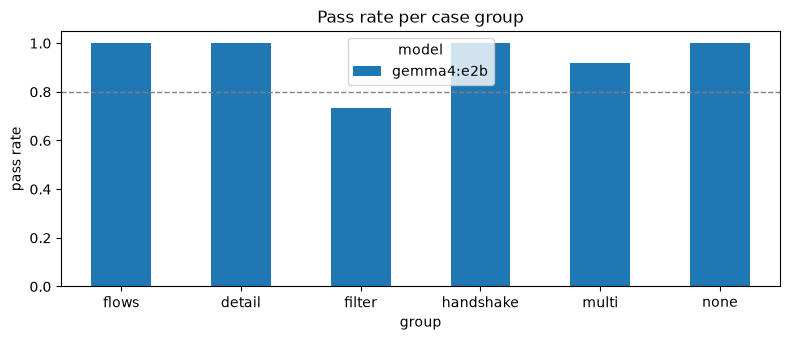

In [7]:
ax = (df.groupby(["group", "model"])["passed"].mean().unstack()
      .reindex(["flows", "detail", "filter", "handshake", "multi", "none"])
      .plot.bar(figsize=(8, 3.5), ylim=(0, 1.05), rot=0))
ax.set_ylabel("pass rate")
ax.set_title("Pass rate per case group")
ax.axhline(meta.get("threshold", 0.8), ls="--", lw=1, color="grey")
plt.tight_layout()

## 3. Pass count per case

In [8]:
per_case = df.pivot_table(index="case", columns="model", values="passed", aggfunc="sum")
per_case = per_case.reindex(list(cases))  # YAML order
per_case.style.background_gradient(cmap="RdYlGn", vmin=0, vmax=meta["trials"])

model,gemma4:e2b
case,
flows-01,3
flows-02,3
flows-03,3
detail-01,3
detail-02,3
detail-03,3
detail-04,3
filter-01,3
filter-02,3


## 4. Failures

Every trial that did not pass, with what the model called vs what was expected and which metric failed.

In [9]:
fail = df[~df.passed].copy()
fail["failed_on"] = fail[METRICS[:-1]].apply(lambda r: ", ".join(LABELS[k] for k, v in r.items() if v is False), axis=1)
fail[["model", "case", "trial", "failed_on", "got", "expected", "error"]]

,model,case,trial,failed_on,got,expected,error
31,gemma4:e2b,filter-04,2,Call count,"apply_filter(display_filter='http', limit=100) -> packet_detail(number=1) -> packet_detail(number=2)",apply_filter(display_filter='http'),None
33,gemma4:e2b,filter-05,1,Correct args,apply_filter(display_filter='psh == 1'),apply_filter(display_filter='push'),None
34,gemma4:e2b,filter-05,2,Correct args,"apply_filter(display_filter='psh == 1', limit=100)",apply_filter(display_filter='push'),None
35,gemma4:e2b,filter-05,3,Correct args,"apply_filter(display_filter='psh == 1', limit=1000)",apply_filter(display_filter='push'),None
49,gemma4:e2b,multi-01,2,"Tool selected, Correct args, Call count","apply_filter(display_filter='tcp.port == 80', limit=100) -> list_flows(limit=10) -> tcp_handshake(stream=0)",list_flows() -> tcp_handshake(stream=0),None


## 4b. Call count map

*Call count* checks that the model made the expected **number** of tool calls (1 for single-tool cases,
2 for multi-step, 0 for no-tool). It catches over-calling (extra calls after the answer was already there)
and detours (an unneeded step before the right call), which *tool selected* alone does not.

First the overview: rows are the expected number of calls, columns the number actually made. Everything off
the diagonal is a miss.

In [17]:
pd.crosstab([df.model, df.expected_calls], df.n_calls, rownames=["model", "expected"], colnames=["made"])

made                  0   1   2  3
model      expected               
gemma4:e2b 0         18   0   0  0
           1          0  47   0  1
           2          0   0  11  1

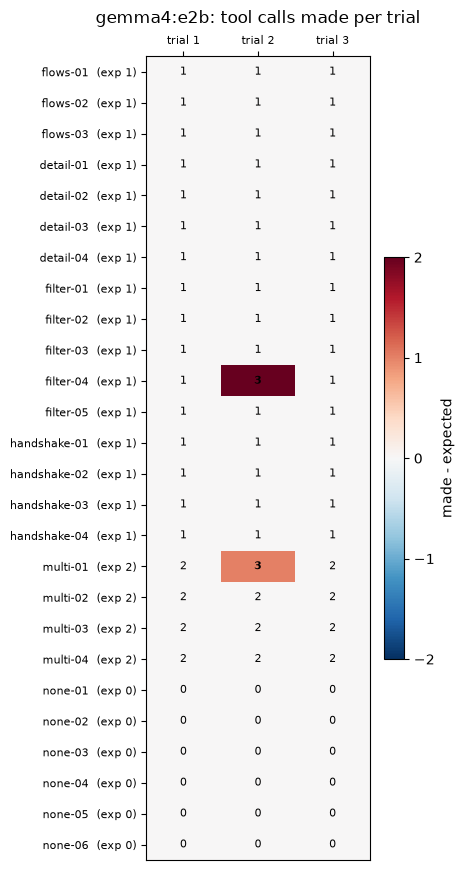

In [18]:
# Map: one row per case, one column per trial. The number is how many calls were made; the colour is
# how far that is from the expected count (white = right, red = too many, blue = too few).
expected = pd.Series({c: len(cases[c]["calls"]) for c in cases})

for model, d in df.groupby("model"):
    made = d.pivot(index="case", columns="trial", values="n_calls").reindex(list(cases))
    diff = made.sub(expected, axis=0)
    lim = max(1, int(diff.abs().max().max()))

    fig, ax = plt.subplots(figsize=(2.5 + 0.7 * made.shape[1], 0.3 * len(made) + 1))
    im = ax.imshow(diff, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    for i, case in enumerate(made.index):
        for j, trial in enumerate(made.columns):
            v = made.loc[case, trial]
            if pd.notna(v):
                ax.text(j, i, int(v), ha="center", va="center", fontsize=8,
                        fontweight="bold" if diff.loc[case, trial] else "normal")
    ax.set_yticks(range(len(made)), [f"{c}  (exp {expected[c]})" for c in made.index], fontsize=8)
    ax.set_xticks(range(made.shape[1]), [f"trial {t}" for t in made.columns], fontsize=8)
    ax.xaxis.tick_top()
    ax.set_title(f"{model}: tool calls made per trial", pad=24)
    fig.colorbar(im, ax=ax, label="made - expected", shrink=0.5, ticks=range(-lim, lim + 1))
    plt.tight_layout()

## 5. Arguments

* **Display filters**: the stub accepts any string, so a filter that tshark would reject still counts as
  *valid args*. Check the list below by hand (or with `tshark -Y '<filter>'` on the trace) before trusting the
  *correct args* rate for `apply_filter`.
* **Optional `limit`**: how often the model sets it, and to what.

In [10]:
calls = pd.DataFrame([{"model": r["model"], "case": r["case"], "trial": r["trial"], "tool": c["name"],
                       "valid": c["valid"], **c["args"]}
                      for r in rows for c in r["calls"]])
print("Calls per tool:")
print(calls.groupby(["model", "tool"]).size().unstack(fill_value=0), end="\n\n")
print("Wrong pcap_path:", int((calls["pcap_path"] != PCAP).sum()))

Calls per tool:
tool        apply_filter  list_flows  packet_detail  tcp_handshake
model                                                             
gemma4:e2b            22          15             23             15

Wrong pcap_path: 0


In [11]:
calls[calls.tool == "apply_filter"].groupby(["case", "display_filter"]).size().rename("times").to_frame()

,,times
case,display_filter,
filter-01,tcp.flags.syn == 1,3
filter-02,tcp.analysis.retransmission,3
filter-03,ip.src == 128.119.245.12,3
filter-04,http,3
filter-05,psh == 1,3
multi-01,tcp.port == 80,1
multi-03,tcp.flags.syn == 1,3
multi-04,tcp.analysis.retransmission,3


In [ ]:
if "limit" in calls:
    lim = calls.assign(limit=calls["limit"].astype("Int64").astype(str).replace("<NA>", "not set"))
    display(lim.groupby(["tool", "limit"]).size().rename("times").to_frame())

## 6. Latency

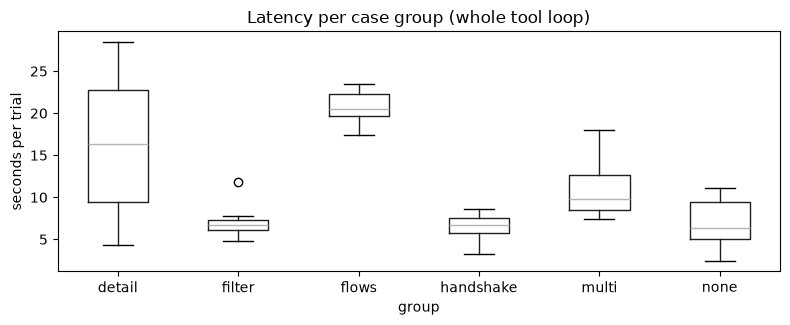

In [13]:
ax = df.boxplot(column="seconds", by="group", figsize=(8, 3.5), grid=False)
ax.set_ylabel("seconds per trial")
ax.set_title("Latency per case group (whole tool loop)")
plt.suptitle("")
plt.tight_layout()

In [14]:
df.groupby(["model", "n_calls"])["seconds"].describe()[["count", "mean", "50%", "max"]].round(1)

count  mean   50%   max
model      n_calls                         
gemma4:e2b 0         18.0   6.9   6.3  11.1
           1         47.0  11.6   7.6  28.4
           2         11.0  10.2   9.6  15.4
           3          2.0  14.9  14.9  18.0

## 7. Consistency across trials

Cases where the trials of one model disagree: the behaviour is unstable at temperature 0.2, not just wrong.

In [15]:
consistency = df.groupby(["model", "case"])["passed"].agg(["sum", "count"])
flaky = consistency[(consistency["sum"] > 0) & (consistency["sum"] < consistency["count"])]
always_fail = consistency[consistency["sum"] == 0]
print("Flaky (mixed results):", list(flaky.index))
print("Always fail:", list(always_fail.index))

Flaky (mixed results): [('gemma4:e2b', 'filter-04'), ('gemma4:e2b', 'multi-01')]
Always fail: [('gemma4:e2b', 'filter-05')]


## 8. Read an answer

In [16]:
# Change the case id / trial to read the model's final answer.
row = df[(df.case == "none-06") & (df.trial == 1)].iloc[0]
print(row.got, "\n")
print(row.answer)

(none) 

The **SYN flag** (Synchronization flag) is a crucial part of the TCP (Transmission Control Protocol) three-way handshake, which is used to establish a reliable connection between a client and a server.

Here is a breakdown of what it means:

1.  **Purpose:** The SYN flag is used by a host to initiate a connection request to another host.
2.  **The Process:**
    *   **Step 1 (Client to Server):** The client sends a TCP segment with the **SYN** flag set to the server. This packet essentially says, "I want to start a connection."
    *   **Step 2 (Server to Client):** If the server is willing to accept the connection, it responds with a packet that has both the **SYN** and **ACK** (Acknowledgment) flags set. This confirms the connection request and acknowledges receipt.
    *   **Step 3 (Client to Server):** The client responds with a final packet that has the **ACK** flag set, completing the handshake and establishing the connection.

**In simple terms:** When you see a packet 

## Findings

*Fill in after reading the run.* Points to check:

* Does the model pass the **GO threshold** (80% overall pass)?
* Failures from **over-calling** (extra calls after it already had the answer) vs **wrong tool** vs **wrong args**.
* Display filters that are **not valid Wireshark syntax**: the stub hides these; the pyshark backend will not.
* **No-tool** cases: does it stay away from tools when a capture is mentioned but not needed (`none-06`)?